# Image Captioning on MS COCO with a CLIP Encoder

- **Encoder**: frozen CLIP ViT-B/32 (`openai/clip-vit-base-patch32`). Each image becomes 50 tokens (1 class token + 7 x 7 patches). They are computed **once** and cached to disk.
- **Decoder**: 4-layer Transformer decoder trained from scratch, with causal self-attention and cross-attention over the CLIP tokens.
- **Data**: MS COCO 2014 with the standard **Karpathy split** (113,287 train / 5,000 val / 5,000 test images, 5 captions each).
- **Evaluation**: BLEU-1..4, METEOR, ROUGE-L and CIDEr on the **test** split with the official COCO caption toolkit (`pycocoevalcap`). The val split is only used for early stopping and checkpoint selection.

Because CLIP is frozen, training only runs the decoder on cached features. This is much faster than the Flickr30k notebook, at the cost of no image augmentation.

## Expected data layout

```
coco/
  dataset_coco.json   # Karpathy split (inside caption_datasets.zip)
  train2014/          # COCO_train2014_*.jpg
  val2014/            # COCO_val2014_*.jpg
```

Download (run in a terminal from the project folder, needs ~40 GB free while unzipping):

```bash
mkdir -p coco && cd coco
wget http://images.cocodataset.org/zips/train2014.zip
wget http://images.cocodataset.org/zips/val2014.zip
wget http://cs.stanford.edu/people/karpathy/deepimagesent/caption_datasets.zip
unzip -q train2014.zip && unzip -q val2014.zip && unzip -j caption_datasets.zip dataset_coco.json
rm train2014.zip val2014.zip caption_datasets.zip
```

METEOR and the PTB tokenizer in `pycocoevalcap` need Java (`sudo apt install default-jre`).

## 1. Setup and Configuration

In [1]:
import json
import math
import os
import random
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.meteor.meteor import Meteor
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.tokenizer.ptbtokenizer import PTBTokenizer
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import CLIPImageProcessor, CLIPVisionModel

/home/ankur/image_captioning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ------------------------------
# Paths
# ------------------------------
DATA_ROOT = Path("coco")
KARPATHY_JSON = DATA_ROOT / "dataset_coco.json"
FEATURE_DIR = Path("features_coco")
CHECKPOINT_DIR = Path("checkpoints_coco")

# ViT-B/16 is stronger, but its cached features need ~37 GB instead of ~9.5 GB.
CLIP_NAME = "openai/clip-vit-base-patch32"

# ------------------------------
# Vocabulary and sequence setup
# ------------------------------
MIN_WORD_FREQ = 5
MAX_WORDS = 20  # Longer captions are truncated; <SOS>/<EOS> are added on top.

# ------------------------------
# Model hyperparameters
# ------------------------------
D_MODEL = 512
N_HEAD = 8
N_LAYERS = 4
DIM_FFN = 2048
DROPOUT = 0.1

# ------------------------------
# Training hyperparameters
# ------------------------------
EXTRACT_BATCH_SIZE = 128
BATCH_SIZE = 64
NUM_EPOCHS = 15
LR = 3e-4
WARMUP_STEPS = 1000
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0
LABEL_SMOOTHING = 0.1
EARLY_STOPPING_PATIENCE = 3
NUM_WORKERS = 4
BEAM_SIZE = 3
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLIP_DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32
AMP = DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

LOADER_KWARGS = {"num_workers": NUM_WORKERS, "pin_memory": DEVICE.type == "cuda"}
if NUM_WORKERS > 0:
    # Datasets defined inside a notebook only reach worker processes through fork.
    LOADER_KWARGS["multiprocessing_context"] = "fork"

FEATURE_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = CHECKPOINT_DIR / "best_model.pt"
LAST_CHECKPOINT = CHECKPOINT_DIR / "last_model.pt"


def feature_path(split: str) -> Path:
    return FEATURE_DIR / f"{CLIP_NAME.split('/')[-1]}_{split}.npy"


print(f"Device: {DEVICE} | bf16 autocast: {AMP}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda | bf16 autocast: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 2. Load the Karpathy Split

`restval` images are merged into train, which is the standard setup used by most captioning papers. The JSON already ships lowercased, punctuation-free `tokens` for training and the original `raw` captions for evaluation.

In [3]:
def load_karpathy_split(json_path: Path, data_root: Path) -> dict:
    with open(json_path, encoding="utf-8") as handle:
        images = json.load(handle)["images"]

    splits = {"train": [], "val": [], "test": []}
    for image in images:
        split = "train" if image["split"] == "restval" else image["split"]
        splits[split].append({
            "cocoid": image["cocoid"],
            "path": data_root / image["filepath"] / image["filename"],
            "captions": [sentence["tokens"] for sentence in image["sentences"]],
            "raw": [sentence["raw"].strip() for sentence in image["sentences"]],
        })

    missing = [item["path"] for items in splits.values() for item in items if not item["path"].exists()]
    if missing:
        raise FileNotFoundError(f"{len(missing):,} images are missing, e.g. {missing[0]}")

    for name, items in splits.items():
        print(f"{name:>5}: {len(items):,} images | {sum(len(item['captions']) for item in items):,} captions")
    return splits


splits = load_karpathy_split(KARPATHY_JSON, DATA_ROOT)

train: 113,287 images | 566,747 captions
  val: 5,000 images | 25,010 captions
 test: 5,000 images | 25,010 captions


## 3. Vocabulary

Built from training captions only. Words seen fewer than `MIN_WORD_FREQ` times map to `<UNK>`.

In [4]:
class Vocabulary:
    PAD, SOS, EOS, UNK = "<PAD>", "<SOS>", "<EOS>", "<UNK>"
    PAD_IDX, SOS_IDX, EOS_IDX, UNK_IDX = 0, 1, 2, 3

    def __init__(self, itos):
        self.itos = list(itos)
        self.stoi = {word: idx for idx, word in enumerate(self.itos)}

    @classmethod
    def build(cls, token_lists, min_freq: int):
        counter = Counter(token for tokens in token_lists for token in tokens)
        words = [word for word, count in counter.most_common() if count >= min_freq]
        return cls([cls.PAD, cls.SOS, cls.EOS, cls.UNK] + words)

    def encode(self, tokens):
        return [self.stoi.get(token, self.UNK_IDX) for token in tokens]

    def decode(self, ids) -> str:
        words = []
        for idx in ids:
            if idx == self.EOS_IDX:
                break
            if idx not in (self.PAD_IDX, self.SOS_IDX):
                words.append(self.itos[idx])
        return " ".join(words)

    def __len__(self) -> int:
        return len(self.itos)


train_token_lists = [tokens for item in splits["train"] for tokens in item["captions"]]
vocab = Vocabulary.build(train_token_lists, MIN_WORD_FREQ)
truncated = sum(len(tokens) > MAX_WORDS for tokens in train_token_lists)

print(f"Vocabulary size: {len(vocab):,}")
print(f"Captions truncated at {MAX_WORDS} words: {truncated:,} ({100 * truncated / len(train_token_lists):.2f}%)")
print(f"Round trip: {vocab.decode(vocab.encode('a man riding a wave on top of a surfboard'.split()))}")

Vocabulary size: 9,997
Captions truncated at 20 words: 3,417 (0.60%)
Round trip: a man riding a wave on top of a surfboard


## 4. Cache CLIP Features

Every image goes through CLIP once and its `(50, 768)` last hidden state is stored as float16 in one `.npy` file per split (~9.5 GB in total for ViT-B/32). Files are written under a `.partial` name and renamed only when complete, so an interrupted run is redone rather than silently used. Re-running this cell skips splits that are already cached.

In [5]:
clip_processor = CLIPImageProcessor.from_pretrained(CLIP_NAME)
clip_model = CLIPVisionModel.from_pretrained(CLIP_NAME, dtype=CLIP_DTYPE).to(DEVICE).eval()
FEATURE_DIM = clip_model.config.hidden_size


class ImageFiles(Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int) -> torch.Tensor:
        image = Image.open(self.paths[index]).convert("RGB")
        return clip_processor(images=image, return_tensors="pt")["pixel_values"][0]


@torch.no_grad()
def cache_features(split: str) -> None:
    out_path = feature_path(split)
    if out_path.exists():
        print(f"Using cached {out_path}")
        return

    partial_path = out_path.with_suffix(".partial.npy")
    loader = DataLoader(ImageFiles([item["path"] for item in splits[split]]), batch_size=EXTRACT_BATCH_SIZE, **LOADER_KWARGS)
    features, offset = None, 0
    for pixels in tqdm(loader, desc=f"CLIP {split}"):
        hidden = clip_model(pixel_values=pixels.to(DEVICE, CLIP_DTYPE)).last_hidden_state
        if features is None:
            shape = (len(splits[split]), *hidden.shape[1:])
            features = np.lib.format.open_memmap(partial_path, mode="w+", dtype=np.float16, shape=shape)
        features[offset:offset + len(hidden)] = hidden.cpu().numpy().astype(np.float16)
        offset += len(hidden)

    features.flush()
    del features
    os.replace(partial_path, out_path)


for split in splits:
    cache_features(split)

for split in splits:
    print(f"{split:>5}: {np.load(feature_path(split), mmap_mode='r').shape}")
print(f"Cache size: {sum(feature_path(split).stat().st_size for split in splits) / 1e9:.1f} GB")

Loading weights: 100%|█████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 3044.59it/s]
[transformers] CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.final_layer_norm.bias                             | UNEXPECTED |  | 
te

train: (113287, 50, 768)
  val: (5000, 50, 768)
 test: (5000, 50, 768)
Cache size: 9.5 GB


## 5. Datasets and DataLoaders

One sample per caption, so each image is seen five times per epoch with a different caption. Features are opened lazily as a memory map in each worker, so workers share the OS page cache instead of each loading the full array.

In [6]:
class CaptionFeatureDataset(Dataset):
    def __init__(self, split: str, vocab: Vocabulary, max_words: int):
        self.feature_file = feature_path(split)
        self.features = None
        self.samples = [
            (index, [Vocabulary.SOS_IDX] + vocab.encode(tokens[:max_words]) + [Vocabulary.EOS_IDX])
            for index, item in enumerate(splits[split])
            for tokens in item["captions"]
        ]

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, index: int):
        if self.features is None:
            self.features = np.load(self.feature_file, mmap_mode="r")
        image_index, token_ids = self.samples[index]
        return torch.from_numpy(np.array(self.features[image_index])), torch.tensor(token_ids)


def collate(batch):
    features, captions = zip(*batch)
    return torch.stack(features), pad_sequence(captions, batch_first=True, padding_value=Vocabulary.PAD_IDX)


train_loader = DataLoader(CaptionFeatureDataset("train", vocab, MAX_WORDS), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, **LOADER_KWARGS)
val_loader = DataLoader(CaptionFeatureDataset("val", vocab, MAX_WORDS), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate, **LOADER_KWARGS)

sample_features, sample_captions = next(iter(train_loader))
print(f"Train batches per epoch: {len(train_loader):,} | Val batches: {len(val_loader):,}")
print(f"Feature batch: {tuple(sample_features.shape)} {sample_features.dtype} | Caption batch: {tuple(sample_captions.shape)}")
print(f"First caption: {vocab.decode(sample_captions[0, 1:].tolist())}")

Train batches per epoch: 8,856 | Val batches: 391
Feature batch: (64, 50, 768) torch.float16 | Caption batch: (64, 20)
First caption: a man on a surfboard surfing in the ocean


## 6. Model

CLIP tokens are projected `768 -> 512` and used as the decoder's cross-attention memory. Decoding uses beam search with **trigram blocking**: a word that would repeat a 3-word phrase already in the caption gets zero probability, which stops loops like *"a girl in a pink shirt and a girl in a pink shirt"*.

In [7]:
class CaptionModel(nn.Module):
    """
    features -> (B, 50, feature_dim)   cached CLIP last hidden state
    captions -> (B, T)                 <SOS> w1 ... wn <EOS> <PAD> ...
    logits   -> (B, T - 1, vocab_size) teacher-forced next-word predictions
    """

    def __init__(self, vocab_size, feature_dim, max_len, d_model, n_head, n_layers, dim_ffn, dropout):
        super().__init__()
        self.proj = nn.Sequential(nn.Linear(feature_dim, d_model), nn.LayerNorm(d_model), nn.Dropout(dropout))
        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=Vocabulary.PAD_IDX)
        self.pos = nn.Embedding(max_len, d_model)
        self.dropout = nn.Dropout(dropout)
        layer = nn.TransformerDecoderLayer(d_model, n_head, dim_ffn, dropout, batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(layer, n_layers, norm=nn.LayerNorm(d_model))
        self.fc_out = nn.Linear(d_model, vocab_size)

    def encode(self, features: torch.Tensor) -> torch.Tensor:
        return self.proj(features.float())

    def decode(self, tokens: torch.Tensor, memory: torch.Tensor) -> torch.Tensor:
        length = tokens.size(1)
        x = self.dropout(self.embed(tokens) + self.pos(torch.arange(length, device=tokens.device)))
        causal_mask = torch.triu(torch.ones(length, length, dtype=torch.bool, device=tokens.device), diagonal=1)
        x = self.decoder(x, memory, tgt_mask=causal_mask, tgt_key_padding_mask=tokens.eq(Vocabulary.PAD_IDX))
        return self.fc_out(x)

    def forward(self, features: torch.Tensor, captions: torch.Tensor) -> torch.Tensor:
        return self.decode(captions[:, :-1], self.encode(features))

    @staticmethod
    def _repeated_ngram_tokens(sequence, n: int = 3) -> set:
        # Tokens that would complete an n-gram already present in the sequence.
        prefix = sequence[len(sequence) - n + 1:]
        return {
            sequence[i + n - 1]
            for i in range(len(sequence) - n + 1)
            if sequence[i:i + n - 1] == prefix
        }

    @torch.no_grad()
    def generate(self, features: torch.Tensor, vocab: Vocabulary, beam_size: int = 3, max_words: int = MAX_WORDS) -> str:
        """Beam search for one image. `features` is (50, feature_dim). All live beams run as one batch."""
        memory = self.encode(features.unsqueeze(0))
        beams, completed = [(0.0, [Vocabulary.SOS_IDX])], []

        for _ in range(max_words + 1):
            tokens = torch.tensor([sequence for _, sequence in beams], device=memory.device)
            logits = self.decode(tokens, memory.expand(len(beams), -1, -1))[:, -1]
            log_probs = F.log_softmax(logits.float(), dim=-1)

            candidates = []
            for row, (score, sequence) in enumerate(beams):
                log_probs[row, list(self._repeated_ngram_tokens(sequence))] = float("-inf")
                values, indices = log_probs[row].topk(beam_size)
                candidates += [(score + value, sequence + [index]) for value, index in zip(values.tolist(), indices.tolist())]

            candidates.sort(key=lambda item: item[0], reverse=True)
            beams = []
            for score, sequence in candidates[:beam_size]:
                (completed if sequence[-1] == Vocabulary.EOS_IDX else beams).append((score, sequence))
            if not beams:
                break

        completed += beams
        _, best_sequence = max(completed, key=lambda item: item[0] / len(item[1]))
        return vocab.decode(best_sequence[1:])


assert CaptionModel._repeated_ngram_tokens([1, 2, 3, 1, 2]) == {3}
assert CaptionModel._repeated_ngram_tokens([1, 2, 3, 4]) == set()

In [8]:
MODEL_CONFIG = {
    "vocab_size": len(vocab),
    "feature_dim": FEATURE_DIM,
    "max_len": MAX_WORDS + 2,
    "d_model": D_MODEL,
    "n_head": N_HEAD,
    "n_layers": N_LAYERS,
    "dim_ffn": DIM_FFN,
    "dropout": DROPOUT,
}
model = CaptionModel(**MODEL_CONFIG).to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
TOTAL_STEPS = NUM_EPOCHS * len(train_loader)


def lr_lambda(step: int) -> float:
    warmup = min(1.0, (step + 1) / WARMUP_STEPS)
    cosine = 0.5 * (1 + math.cos(math.pi * min(step / TOTAL_STEPS, 1.0)))
    return warmup * cosine


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
criterion = nn.CrossEntropyLoss(ignore_index=Vocabulary.PAD_IDX, label_smoothing=LABEL_SMOOTHING)

with torch.no_grad():
    sample_logits = model(sample_features.to(DEVICE), sample_captions.to(DEVICE))

print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Features {tuple(sample_features.shape)} -> logits {tuple(sample_logits.shape)} | targets {tuple(sample_captions[:, 1:].shape)}")

Trainable parameters: 27,470,093
Features (64, 50, 768) -> logits (64, 19, 9997) | targets (64, 19)


## 7. Training

Saves `best_model.pt` whenever val loss improves and `last_model.pt` every epoch. **Re-running this cell resumes from `last_model.pt`**, including after early stopping (it then just stops again), so a crash or a closed laptop doesn't lose progress. Delete `checkpoints_coco/` to train from scratch.

Epoch 01/15 | train_loss=3.6246 | val_loss=3.2734 | lr=2.97e-04 | 6.9 min


Epoch 02/15 | train_loss=3.2089 | val_loss=3.1708 | lr=2.87e-04 | 6.9 min


Epoch 03/15 | train_loss=3.1062 | val_loss=3.1225 | lr=2.71e-04 | 6.9 min


Epoch 04/15 | train_loss=3.0359 | val_loss=3.0964 | lr=2.50e-04 | 6.8 min


Epoch 05/15 | train_loss=2.9784 | val_loss=3.0763 | lr=2.25e-04 | 7.1 min


...

Epoch 07/15 | train_loss=2.8806 | val_loss=3.0627 | lr=1.66e-04 | 7.2 min


Epoch 08/15 | train_loss=2.8363 | val_loss=3.0592 | lr=1.34e-04 | 7.2 min


Epoch 09/15 | train_loss=2.7943 | val_loss=3.0607 | lr=1.04e-04 | 6.9 min


Epoch 10/15 | train_loss=2.7564 | val_loss=3.0658 | lr=7.50e-05 | 6.8 min


Epoch 11/15 | train_loss=2.7222 | val_loss=3.0701 | lr=4.96e-05 | 7.1 min
Early stopping: no val improvement for 3 epochs.


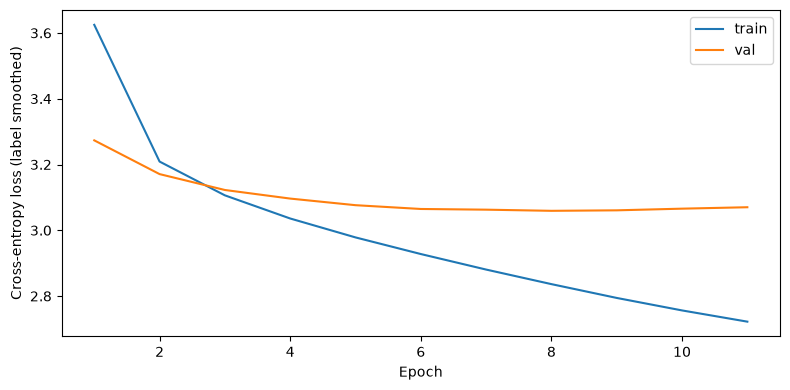

Best val loss: 3.0592


In [9]:
def save_checkpoint(path: Path, **state) -> None:
    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "vocab": vocab.itos,
        "model_config": MODEL_CONFIG,
        "clip_name": CLIP_NAME,
        **state,
    }, path)


def run_epoch(loader: DataLoader, train: bool) -> float:
    model.train(train)
    total_loss, total_tokens = 0.0, 0
    with torch.set_grad_enabled(train):
        for features, captions in tqdm(loader, desc="train" if train else "val", leave=False):
            features = features.to(DEVICE, non_blocking=True)
            captions = captions.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=AMP):
                logits = model(features, captions)
            targets = captions[:, 1:]
            loss = criterion(logits.float().flatten(0, 1), targets.flatten())

            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step()
                scheduler.step()

            tokens = int(targets.ne(Vocabulary.PAD_IDX).sum())
            total_loss += loss.item() * tokens
            total_tokens += tokens
    return total_loss / total_tokens


history = {"train": [], "val": []}
best_val_loss, start_epoch, stale_epochs = float("inf"), 1, 0

if LAST_CHECKPOINT.exists():
    checkpoint = torch.load(LAST_CHECKPOINT, map_location=DEVICE, weights_only=True)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    history, best_val_loss = checkpoint["history"], checkpoint["best_val_loss"]
    start_epoch, stale_epochs = checkpoint["epoch"] + 1, checkpoint["stale_epochs"]
    print(f"Resuming after epoch {checkpoint['epoch']} (delete {CHECKPOINT_DIR}/ to start fresh)")

for epoch in range(start_epoch, NUM_EPOCHS + 1):
    if stale_epochs >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping: no val improvement for {stale_epochs} epochs.")
        break

    started = time.time()
    train_loss = run_epoch(train_loader, train=True)
    val_loss = run_epoch(val_loader, train=False)
    history["train"].append(train_loss)
    history["val"].append(val_loss)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss, stale_epochs = val_loss, 0
        save_checkpoint(BEST_CHECKPOINT, epoch=epoch)
    else:
        stale_epochs += 1
    save_checkpoint(LAST_CHECKPOINT, epoch=epoch, history=history, best_val_loss=best_val_loss, stale_epochs=stale_epochs)

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
        f"lr={scheduler.get_last_lr()[0]:.2e} | {(time.time() - started) / 60:.1f} min"
    )

fig, ax = plt.subplots(figsize=(8, 4))
epochs = range(1, len(history["train"]) + 1)
ax.plot(epochs, history["train"], label="train")
ax.plot(epochs, history["val"], label="val")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss (label smoothed)")
ax.legend()
fig.tight_layout()
fig.savefig(CHECKPOINT_DIR / "loss_curve.png", dpi=150)
plt.show()
print(f"Best val loss: {best_val_loss:.4f}")

## 8. Test-Set Evaluation

Loads the best checkpoint (picked by **val** loss) and scores beam-search captions for the 5,000 **test** images against their reference captions, using the same tokenizer and scorers as published COCO results. CIDEr is the main metric in captioning papers; BLEU is reported for completeness.

In [10]:
best_checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE, weights_only=True)
vocab = Vocabulary(best_checkpoint["vocab"])
model.load_state_dict(best_checkpoint["model"])
model.eval()
print(f"Loaded best checkpoint from epoch {best_checkpoint['epoch']}")


def evaluate(split: str):
    items = splits[split]
    features = np.load(feature_path(split), mmap_mode="r")
    predictions = {
        item["cocoid"]: model.generate(torch.from_numpy(np.array(features[index])).to(DEVICE), vocab, BEAM_SIZE)
        for index, item in enumerate(tqdm(items, desc=f"Captioning {split}"))
    }

    tokenizer = PTBTokenizer()
    references = tokenizer.tokenize({item["cocoid"]: [{"caption": raw} for raw in item["raw"]] for item in items})
    hypotheses = tokenizer.tokenize({cocoid: [{"caption": caption}] for cocoid, caption in predictions.items()})

    scores = {}
    for name, scorer in [("BLEU", Bleu(4)), ("METEOR", Meteor()), ("ROUGE-L", Rouge()), ("CIDEr", Cider())]:
        score, _ = scorer.compute_score(references, hypotheses)
        if name == "BLEU":
            scores.update({f"BLEU-{n}": value for n, value in enumerate(score, start=1)})
        else:
            scores[name] = score
    return predictions, {name: round(100 * value, 2) for name, value in scores.items()}


test_predictions, test_scores = evaluate("test")

with open(CHECKPOINT_DIR / "test_predictions.json", "w", encoding="utf-8") as handle:
    json.dump(test_predictions, handle, indent=1)
with open(CHECKPOINT_DIR / "test_scores.json", "w", encoding="utf-8") as handle:
    json.dump(test_scores, handle, indent=1)

for name, value in test_scores.items():
    print(f"{name:>8}: {value:.2f}")

Loaded best checkpoint from epoch 8


Captioning test: 100%|█████████████████████████████████████████████████████████████| 5000/5000 [07:30<00:00, 11.10it/s]
PTBTokenizer tokenized 307085 tokens at 977845.59 tokens per second.
PTBTokenizer tokenized 56237 tokens at 618565.97 tokens per second.


{'testlen': 51238, 'reflen': 49958, 'guess': [51238, 46238, 41238, 36238], 'correct': [37731, 20619, 10522, 5358]}
ratio: 1.0256215220785254
  BLEU-1: 73.64
  BLEU-2: 57.30
  BLEU-3: 43.76
  BLEU-4: 33.36
  METEOR: 28.15
 ROUGE-L: 55.92
   CIDEr: 112.67


## 9. Sample Predictions and Custom Images

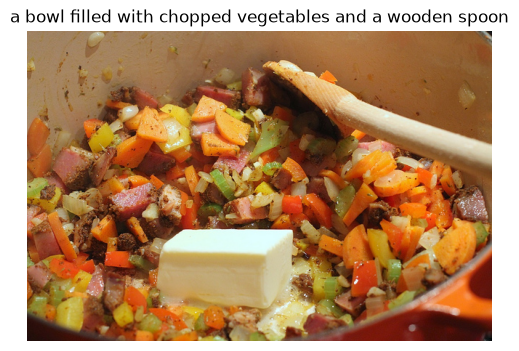

References:
- A pan filled with veggies and a block of butter.
- Butter or cheese on top of some vegetables in a pan.
- Spoon in a bowl of chopped vegetables with butter
- A pan with butter and other ingredients for a dish.
- Pot with variety of chopped vegetables, big chunk of butter and spoon.
--------------------------------------------------------------------------------


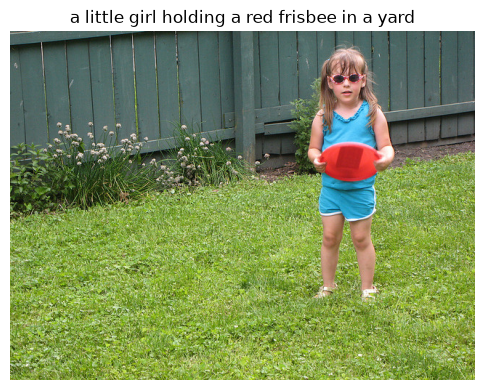

References:
- A little girl holding a red frisbee standing on a lush green field.
- A little girl in the grass wearing sunglasses holding a frisbee.
- A young girl is holding a Frisbee in the grass
- Young girl in sunglasses standing in a lawn, holding a frisbee
- A girl in blue shit and shorts holding a frisbee in grassy area.
--------------------------------------------------------------------------------


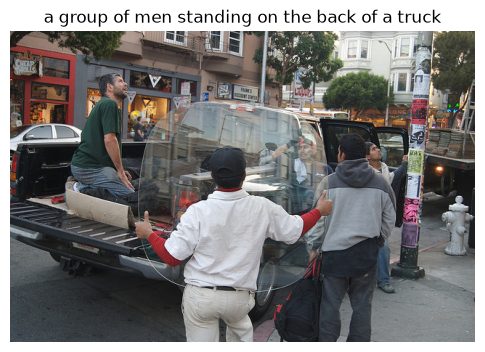

References:
- a person holding a clear piece of glass or plastic
- A man holding a large piece of glass outside by a truck
- a couple of men are loading a truck with glass
- Many men work together to put objects in a truck.
- A man holding glass near a pick up truck on the street.
--------------------------------------------------------------------------------


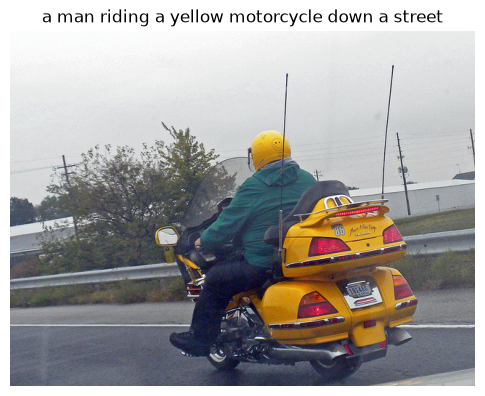

References:
- A man rides a large motorcycle on a freeway.
- A man riding a motorcycle in overcast weather
- A man rides a yellow motorcycle down a street.
- A photo taken from a vehicle at a man on a yellow motorcycle.
- Man with yellow helmet riding a yellow motorcycle
--------------------------------------------------------------------------------


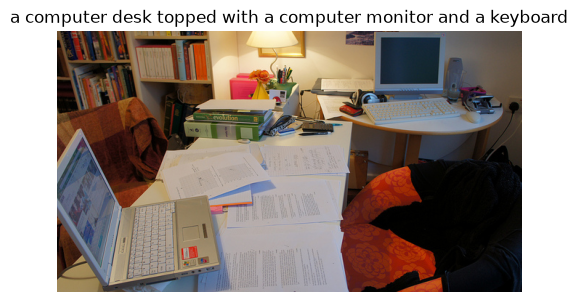

References:
- A picture of a cluttered home office desk.
- Laptop computer on long desk with assorted paperwork.
- In home desk, covered with papers and two computers.
- A white desk is covered with papers and has a silver lap top on it.
- The desk with a laptop has papers strewn all over it.
--------------------------------------------------------------------------------


In [11]:
for index in random.Random(SEED).sample(range(len(splits["test"])), 5):
    item = splits["test"][index]
    plt.figure(figsize=(6, 6))
    plt.imshow(Image.open(item["path"]).convert("RGB"))
    plt.axis("off")
    plt.title(test_predictions[item["cocoid"]], wrap=True)
    plt.show()
    print("References:")
    for raw in item["raw"]:
        print(f"- {raw}")
    print("-" * 80)

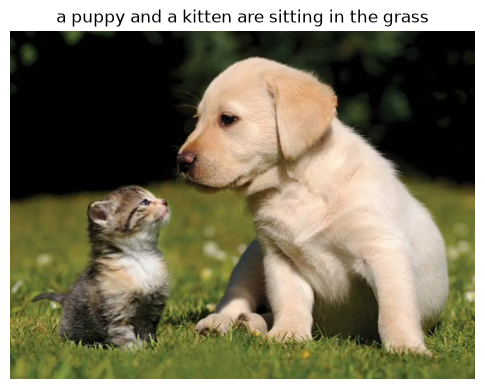

Generated caption: a puppy and a kitten are sitting in the grass


In [12]:
@torch.no_grad()
def caption_image(path) -> str:
    image = Image.open(path).convert("RGB")
    pixels = clip_processor(images=image, return_tensors="pt")["pixel_values"]
    features = clip_model(pixel_values=pixels.to(DEVICE, CLIP_DTYPE)).last_hidden_state[0]
    return model.generate(features, vocab, BEAM_SIZE)


CUSTOM_IMAGE_PATH = "test.jpg"

caption = caption_image(CUSTOM_IMAGE_PATH)
plt.figure(figsize=(6, 6))
plt.imshow(Image.open(CUSTOM_IMAGE_PATH).convert("RGB"))
plt.axis("off")
plt.title(caption, wrap=True)
plt.show()
print(f"Generated caption: {caption}")

## 10. Results

Scores on the 5,000-image Karpathy **test** split (`checkpoints_coco/test_scores.json`). The other rows are published **cross-entropy-trained** results (no reinforcement-learning fine-tuning) on the same split, from Table 1 of the ClipCap paper (Mokady et al., 2021).

| Model | Trainable params | BLEU-4 | METEOR | CIDEr |
| :--- | :---: | :---: | :---: | :---: |
| **This notebook (CLIP ViT-B/32 + Transformer)** | 27M | **33.4** | **28.2** | **112.7** |
| Bottom-Up Top-Down (Anderson et al., 2018) | 52M | 36.2 | 27.0 | 113.5 |
| ClipCap, Transformer + frozen GPT-2 (Mokady et al., 2021) | 43M | 33.5 | 27.5 | 113.1 |
| ClipCap, MLP + fine-tuned GPT-2 (Mokady et al., 2021) | 156M | 32.2 | 27.1 | 108.4 |

Full test scores: BLEU-1 73.64, BLEU-2 57.30, BLEU-3 43.76, BLEU-4 33.36, METEOR 28.15, ROUGE-L 55.92, CIDEr 112.67. Best checkpoint: epoch 8 of 11 (early stopping).